# Phase-Aware Predictive Maintenance for Drill Bit Monitoring
This notebook implements a full ML pipeline for drill bit health classification using multi-sensor data.

**Pipeline Overview:**
1. Load & tag raw CSV data
2. Preprocess (timestamps, interpolation) + Phase Detection
3. Sliding-window feature extraction (3 dataset variants)
4. Trial-level train/val/test split (no leakage)
5. Train & evaluate 4 classifiers with cross-validation
6. Sensor contribution analysis
7. Health scoring & maintenance recommendations
8. Visualisations

## 0 — Imports & Configuration

In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from tqdm.notebook import tqdm
from scipy.stats import kurtosis, skew
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)
from xgboost import XGBClassifier
from xgboost.callback import TrainingCallback

warnings.filterwarnings('ignore')
np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 110
print('All imports OK')

All imports OK


In [2]:
# ── Sliding-window parameters ────────────────────────────────────
WINDOW_SIZE = 20
STEP_SIZE   = 10

# ── Health score mapping ─────────────────────────────────────────
HEALTH_SCORES = {
    'good_aligned':     100,
    'good_misaligned':   85,
    'good_flattened':    70,
    'poor_aligned':      60,
    'poor_misaligned':   45,
    'good_broken':       30,
    'poor_flattened':    20,
    'poor_broken':        0,
}

# ── CSV filename → label mapping ─────────────────────────────────
FILE_LABEL_MAP = {
    'good_aligned_ok.csv':      'good_aligned',
    'good_aligned_flat.csv':    'good_flattened',
    'good_aligned_broken.csv':  'good_broken',
    'good_misaligned_ok.csv':   'good_misaligned',
    'poor_aligned_ok.csv':      'poor_aligned',
    'poor_aligned_flat.csv':    'poor_flattened',
    'poor_aligned_broken.csv':  'poor_broken',
    'poor_misaligned_ok.csv':   'poor_misaligned',
}

# ── Set your data directory here ─────────────────────────────────
DATA_DIR = '.'   # <-- change to your CSV folder if needed
print('Configuration loaded')

Configuration loaded


## 1 — Load Raw Data

In [3]:
def load_all_data(data_dir: str = '.') -> pd.DataFrame:
    """Load all 8 CSV files and tag with label + global trial ID."""
    frames = []
    global_trial = 0

    for fname, label in FILE_LABEL_MAP.items():
        path = os.path.join(data_dir, fname)
        if not os.path.exists(path):
            print(f'[WARN] File not found: {path} — skipping')
            continue

        df = pd.read_csv(path)
        df.columns = df.columns.str.strip()

        rename = {}
        for c in df.columns:
            cl = c.lower()
            if   'timestamp' in cl:                   rename[c] = 'Timestamp'
            elif 'trial'     in cl:                   rename[c] = 'Trial_No'
            elif 'current'   in cl:                   rename[c] = 'Current_A'
            elif 'power'     in cl or 'voltage' in cl:rename[c] = 'Power_V'
            elif 'lm35'      in cl:                   rename[c] = 'LM35_Tem'
            elif 'dht'       in cl:                   rename[c] = 'DHT_Tem'
            elif 'humid'     in cl:                   rename[c] = 'Humidity'
            elif 'vib'       in cl:                   rename[c] = 'Vib_Strength'
        df.rename(columns=rename, inplace=True)

        df['Label']     = label
        df['Quality']   = label.split('_')[0]
        df['Condition'] = '_'.join(label.split('_')[1:])

        for local_trial in df['Trial_No'].unique():
            mask = df['Trial_No'] == local_trial
            df.loc[mask, 'Global_Trial'] = global_trial
            global_trial += 1

        frames.append(df)
        print(f'[OK] {fname} → {label} | rows={len(df)}')

    if not frames:
        raise FileNotFoundError('No CSV files found. Place CSVs in DATA_DIR.')

    combined = pd.concat(frames, ignore_index=True)
    combined['Global_Trial'] = combined['Global_Trial'].astype(int)
    print(f'\n[INFO] Total rows: {len(combined)} | Trials: {combined["Global_Trial"].nunique()}')
    return combined

In [4]:
raw_df = load_all_data(DATA_DIR)
raw_df.head()

[WARN] File not found: .\good_aligned_ok.csv — skipping
[WARN] File not found: .\good_aligned_flat.csv — skipping
[WARN] File not found: .\good_aligned_broken.csv — skipping
[WARN] File not found: .\good_misaligned_ok.csv — skipping
[WARN] File not found: .\poor_aligned_ok.csv — skipping
[WARN] File not found: .\poor_aligned_flat.csv — skipping
[WARN] File not found: .\poor_aligned_broken.csv — skipping
[WARN] File not found: .\poor_misaligned_ok.csv — skipping


FileNotFoundError: No CSV files found. Place CSVs in DATA_DIR.

In [ ]:
print('Label distribution:')
print(raw_df['Label'].value_counts())
print('\nColumn dtypes:')
print(raw_df.dtypes)

Label distribution:
Label
poor_flattened     3999
good_flattened     3409
good_broken        3168
poor_misaligned    2655
good_misaligned    2271
good_aligned       2245
poor_broken        2029
poor_aligned       1731
Name: count, dtype: int64

Column dtypes:
Timestamp        object
Trial_No          int64
Current_A       float64
Power_V         float64
LM35_Tem        float64
DHT_Tem         float64
Humidity        float64
Vib_Strength      int64
Label            object
Quality          object
Condition        object
Global_Trial      int64
dtype: object


## 2 — Preprocessing & Phase Detection

In [ ]:
def preprocess_trial(df: pd.DataFrame) -> pd.DataFrame:
    """Per-trial preprocessing: timestamps, elapsed time, missing values."""
    df = df.copy().reset_index(drop=True)

    # ── Fix duplicate columns (keep first occurrence) ──────────────
    df = df.loc[:, ~df.columns.duplicated()]

    # ── Parse timestamps ───────────────────────────────────────────
    if "Timestamp" in df.columns:
        try:
            df["Timestamp"] = pd.to_datetime(df["Timestamp"])
            df.sort_values("Timestamp", inplace=True)
            df.reset_index(drop=True, inplace=True)
            t0 = df["Timestamp"].iloc[0]
            df["Elapsed_Time"] = (df["Timestamp"] - t0).dt.total_seconds()
        except Exception:
            df["Elapsed_Time"] = np.arange(len(df)) * 0.1
    else:
        df["Elapsed_Time"] = np.arange(len(df)) * 0.1

    total_dur = df["Elapsed_Time"].iloc[-1]
    df["Trial_Progress"] = df["Elapsed_Time"] / (total_dur if total_dur > 0 else 1)

    # ── Fill missing sensor values ─────────────────────────────────
    for col in ["Current_A", "Power_V", "LM35_Tem", "DHT_Tem",
                "Humidity", "Vib_Strength"]:
        if col in df.columns:
            # Squeeze in case it's a DataFrame instead of Series
            series = df[col]
            if isinstance(series, pd.DataFrame):
                series = series.iloc[:, 0]
            df[col] = pd.to_numeric(series, errors="coerce")
            df[col] = df[col].interpolate(method="linear").ffill().bfill()

    return df


def detect_phases(df: pd.DataFrame) -> pd.DataFrame:
    """
    Assign phase labels using Current_A and Vib_Strength thresholds.
    Phases: Idle | Lowering | Contact | Drilling | Exit | Retraction
    """
    df   = df.copy().reset_index(drop=True)   # ← belt-and-suspenders
    cur  = df['Current_A'].values
    vib  = df['Vib_Strength'].values
    n    = len(df)

    cur_mean  = np.mean(cur);  cur_std = np.std(cur)
    vib_mean  = np.mean(vib)
    cur_high  = cur_mean + 0.5 * cur_std
    cur_low   = cur_mean - 0.3 * cur_std
    vib_thresh= vib_mean

    cur_grad = np.gradient(cur)
    vib_grad = np.gradient(vib)

    phases = []
    for i in range(n):
        c, v   = cur[i], vib[i]
        cg, vg = cur_grad[i], vib_grad[i]
        prog   = i / n
        if   prog < 0.05 or prog > 0.95:                                                  phases.append('Idle')
        elif cg > 0.3*np.std(cur_grad) and vg > 0.2*np.std(vib_grad):                   phases.append('Contact')
        elif c >= cur_high and v >= vib_thresh:                                           phases.append('Drilling')
        elif cg < -0.3*np.std(cur_grad) and prog > 0.4:                                  phases.append('Exit')
        elif c < cur_low and prog > 0.5:                                                  phases.append('Retraction')
        elif v > vib_thresh * 0.5 and c < cur_mean:                                       phases.append('Lowering')
        else:                                                                             phases.append('Idle')

    df['Phase']      = phases
    df['Is_Drilling']= (df['Phase'] == 'Drilling').astype(int)

    contact_rows = df[df['Phase'] == 'Contact']
    if len(contact_rows) > 0:
        contact_time = df.loc[contact_rows.index[0], 'Elapsed_Time']
    else:
        abs_grad = np.abs(cur_grad)
        contact_time = df['Elapsed_Time'].iloc[np.argmax(abs_grad)] if abs_grad.max() > 0 else df['Elapsed_Time'].iloc[0]

    df['Contact_Time']      = contact_time
    df['Time_From_Contact'] = df['Elapsed_Time'] - contact_time
    return df


def preprocess_all(raw_df: pd.DataFrame) -> pd.DataFrame:
    results = []
    for trial_id, grp in tqdm(raw_df.groupby('Global_Trial'), desc='Preprocessing trials'):
        grp = preprocess_trial(grp)
        grp = detect_phases(grp)
        results.append(grp)
    return pd.concat(results, ignore_index=True)

print('Preprocessing functions defined')

Preprocessing functions defined


In [ ]:
processed_df = preprocess_all(raw_df)
print('Phase distribution:')
print(processed_df['Phase'].value_counts())

Preprocessing trials:   0%|          | 0/119 [00:00<?, ?it/s]

Phase distribution:
Phase
Idle          7141
Lowering      4841
Exit          4023
Retraction    2053
Contact       2005
Drilling      1444
Name: count, dtype: int64


## 3 — Feature Extraction (Sliding Window)

In [ ]:
def rms(x): return np.sqrt(np.mean(x**2))

def extract_window_features(window: pd.DataFrame, include_phase: bool = False) -> dict:
    cur = window['Current_A'].values.astype(float)
    vib = window['Vib_Strength'].values.astype(float)
    lm  = window['LM35_Tem'].values.astype(float)
    dht = window['DHT_Tem'].values.astype(float)
    hum = window['Humidity'].values.astype(float)
    et  = window['Elapsed_Time'].values.astype(float)
    tp  = window['Trial_Progress'].values.astype(float)
    tfc = window['Time_From_Contact'].values.astype(float)

    feat = {}
    # Vibration
    feat['vib_mean']    = np.mean(vib);    feat['vib_max']  = np.max(vib)
    feat['vib_min']     = np.min(vib);     feat['vib_std']  = np.std(vib)
    feat['vib_var']     = np.var(vib);     feat['vib_rms']  = rms(vib)
    feat['vib_p2p']     = np.max(vib) - np.min(vib)
    feat['vib_kurtosis']= kurtosis(vib);   feat['vib_skew'] = skew(vib)
    feat['vib_crest']   = (np.max(np.abs(vib)) / rms(vib)) if rms(vib) > 0 else 0
    # Current
    feat['cur_mean']    = np.mean(cur);    feat['cur_max']  = np.max(cur)
    feat['cur_min']     = np.min(cur);     feat['cur_std']  = np.std(cur)
    feat['cur_var']     = np.var(cur);     feat['cur_rms']  = rms(cur)
    # Temperature
    feat['lm35_mean']   = np.mean(lm);     feat['lm35_max'] = np.max(lm)
    feat['dht_mean']    = np.mean(dht);    feat['dht_max']  = np.max(dht)
    feat['temp_rise']   = np.max(lm) - np.min(lm)
    feat['temp_diff']   = np.mean(lm) - np.mean(dht)
    # Humidity
    feat['hum_mean']    = np.mean(hum);    feat['hum_std']  = np.std(hum)
    # Time
    feat['elapsed_mean']= np.mean(et);     feat['trial_prog'] = np.mean(tp)
    feat['tfc_mean']    = np.mean(tfc)
    feat['drill_pct']   = np.mean(window['Is_Drilling'].values)
    # Gradients
    feat['cur_grad']    = np.mean(np.gradient(cur))
    feat['vib_grad']    = np.mean(np.gradient(vib))
    feat['temp_grad']   = np.mean(np.gradient(lm))
    # Sensor fusion
    feat['cur_x_vib']   = feat['cur_mean'] * feat['vib_mean']
    feat['cur_x_temp']  = feat['cur_mean'] * feat['lm35_mean']
    feat['vib_x_temp']  = feat['vib_mean'] * feat['lm35_mean']
    feat['cur_vib_ratio']= (feat['cur_mean'] / feat['vib_mean']) if feat['vib_mean'] != 0 else 0
    # Energy
    dt = np.diff(et, prepend=et[0])
    feat['energy']      = np.sum(np.abs(cur) * np.abs(dt))
    # Phase proportions (Dataset C only)
    if include_phase:
        pc = window['Phase'].value_counts(normalize=True)
        for ph in ['Idle','Lowering','Contact','Drilling','Exit','Retraction']:
            feat[f'phase_{ph.lower()}'] = pc.get(ph, 0.0)
    return feat


def build_dataset(processed_df: pd.DataFrame, variant: str = "A") -> pd.DataFrame:
    records = []
    trials  = list(processed_df.groupby("Global_Trial"))

    print(f"\n[STAGE 3] Feature Extraction — Dataset {variant}")

    skipped = 0
    for trial_id, trial_df in tqdm(trials, desc=f"Extracting features (Dataset {variant})",
                                    unit="trial",
                                    bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{percentage:.0f}%]"):
        trial_df = trial_df.reset_index(drop=True)

        if variant == "B":
            filtered = trial_df[trial_df["Phase"].isin(["Contact", "Drilling"])]
            if len(filtered) < WINDOW_SIZE:
                skipped += 1
                filtered = trial_df   # keep all phases so window can still be built
            trial_df = filtered.reset_index(drop=True)

        n = len(trial_df)
        if n < WINDOW_SIZE:
            skipped += 1
            continue

        label         = trial_df["Label"].iloc[0]
        include_phase = (variant == "C")

        for start in range(0, n - WINDOW_SIZE + 1, STEP_SIZE):
            window = trial_df.iloc[start: start + WINDOW_SIZE]
            feats  = extract_window_features(window, include_phase=include_phase)
            feats["Label"]        = label
            feats["Global_Trial"] = trial_id
            records.append(feats)

    # ── Guard: nothing was extracted ──────────────────────────────
    if not records:
        print(f"[WARN] Dataset {variant}: no windows extracted! "
              f"Returning empty DataFrame.")
        return pd.DataFrame()

    df_feat = pd.DataFrame(records)

    if skipped:
        print(f"[WARN] Dataset {variant}: {skipped} trials had too few "
              f"Contact/Drilling rows — used full trial as fallback.")

    print(f"[INFO] Dataset {variant}: {len(df_feat)} windows | "
          f"{df_feat['Label'].nunique()} classes")
    return df_feat
print('Feature extraction functions defined')

Feature extraction functions defined


In [ ]:
dataset_A = build_dataset(processed_df, variant='A')
dataset_B = build_dataset(processed_df, variant='B')
dataset_C = build_dataset(processed_df, variant='C')

print(f'\nDataset A shape: {dataset_A.shape}')
print(f'Dataset B shape: {dataset_B.shape}')
print(f'Dataset C shape: {dataset_C.shape}')


[STAGE 3] Feature Extraction — Dataset A


Extracting features (Dataset A):   0%|          | 0/119 [0%]

[INFO] Dataset A: 1982 windows | 8 classes

[STAGE 3] Feature Extraction — Dataset B


Extracting features (Dataset B):   0%|          | 0/119 [0%]

[WARN] Dataset B: 26 trials had too few Contact/Drilling rows — used full trial as fallback.
[INFO] Dataset B: 428 windows | 8 classes

[STAGE 3] Feature Extraction — Dataset C


Extracting features (Dataset C):   0%|          | 0/119 [0%]

[INFO] Dataset C: 1982 windows | 8 classes

Dataset A shape: (1982, 38)
Dataset B shape: (428, 38)
Dataset C shape: (1982, 44)


In [ ]:
# Run this right after build_dataset, before trial_level_split
FEATURE_COLS_A = [c for c in dataset_A.columns if c not in ('Label', 'Global_Trial')]
FEATURE_COLS_B = [c for c in dataset_B.columns if c not in ('Label', 'Global_Trial')]
FEATURE_COLS_C = [c for c in dataset_C.columns if c not in ('Label', 'Global_Trial')]

print(f'Dataset A: {len(FEATURE_COLS_A)} features')
print(f'Dataset B: {len(FEATURE_COLS_B)} features')
print(f'Dataset C: {len(FEATURE_COLS_C)} features')

Dataset A: 36 features
Dataset B: 36 features
Dataset C: 42 features


## 4 — Train / Val / Test Split (Trial-Level)

In [ ]:

def trial_level_split(feat_df: pd.DataFrame, train_frac=0.70, val_frac=0.15):
    """Split at trial level to prevent data leakage."""
    train_trials, val_trials, test_trials = [], [], []
    for label, grp in feat_df.groupby('Label'):
        trials = grp['Global_Trial'].unique()
        np.random.shuffle(trials)
        n       = len(trials)
        n_train = max(1, int(n * train_frac))
        n_val   = max(1, int(n * val_frac))
        train_trials.extend(trials[:n_train])
        val_trials.extend(trials[n_train: n_train + n_val])
        test_trials.extend(trials[n_train + n_val:])

    train_df = feat_df[feat_df['Global_Trial'].isin(train_trials)]
    val_df   = feat_df[feat_df['Global_Trial'].isin(val_trials)]
    test_df  = feat_df[feat_df['Global_Trial'].isin(test_trials)]
    print(f'Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}')
    return train_df, val_df, test_df


from sklearn.impute import SimpleImputer

from sklearn.impute import SimpleImputer

from sklearn.impute import SimpleImputer

def get_xy(df: pd.DataFrame, le: LabelEncoder, scaler: StandardScaler = None,
           fit_scaler: bool = False, imputer: SimpleImputer = None,
           fit_imputer: bool = False):
    drop_cols = ["Label", "Global_Trial"]
    X = df.drop(columns=drop_cols, errors="ignore").values.astype(float)
    y = le.transform(df["Label"].values)
    groups = df["Global_Trial"].values

    # ── Impute NaN before scaling ──────────────────────────────────
    if imputer is not None:
        if fit_imputer:
            X = imputer.fit_transform(X)
        else:
            X = imputer.transform(X)

    if fit_scaler and scaler is not None:
        X = scaler.fit_transform(X)
    elif scaler is not None:
        X = scaler.transform(X)

    return X, y, groups

print('get_xy updated')
print('Split helpers defined')

get_xy updated
Split helpers defined


In [ ]:
train_A, val_A, test_A = trial_level_split(dataset_A)
train_B, val_B, test_B = trial_level_split(dataset_B)
train_C, val_C, test_C = trial_level_split(dataset_C)

Train=1318 | Val=253 | Test=411
Train=285 | Val=60 | Test=83
Train=1337 | Val=252 | Test=393


## 5 — Model Training & Evaluation

In [ ]:
from xgboost.callback import TrainingCallback

class XGBoostProgressCallback(TrainingCallback):
    """Shows a tqdm bar that updates every boosting round."""

    def __init__(self, n_estimators: int, fold_bar=None):
        super().__init__()                     # ← was missing before
        self.n_estimators = n_estimators
        self.fold_bar     = fold_bar
        self._bar         = None

    def before_training(self, model):
        if self.fold_bar is None:
            self._bar = tqdm(
                total=self.n_estimators,
                desc="    XGB rounds",
                unit="round",
                leave=False,
                bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{percentage:.0f}%]"
            )
        return model

    def after_iteration(self, model, epoch, evals_log):
        if self._bar:
            self._bar.update(1)
            self._bar.set_postfix({"round": epoch + 1})
        elif self.fold_bar:
            self.fold_bar.set_postfix({"xgb_round": epoch + 1})
        return False

    def after_training(self, model):
        if self._bar:
            self._bar.close()
            self._bar = None
        return model

def extract_window_features(window: pd.DataFrame, include_phase: bool = False) -> dict:
    """Extract all features from a single window."""

    # ── Clean window before extracting ───────────────────────────
    window = window.copy()
    window = window.ffill().bfill().fillna(0)

    cur  = window["Current_A"].values.astype(float)
    vib  = window["Vib_Strength"].values.astype(float)
    lm   = window["LM35_Tem"].values.astype(float)
    dht  = window["DHT_Tem"].values.astype(float)
    hum  = window["Humidity"].values.astype(float)
    et   = window["Elapsed_Time"].values.astype(float)
    tp   = window["Trial_Progress"].values.astype(float)
    tfc  = window["Time_From_Contact"].values.astype(float)

    feat = {}

    # ── Vibration ─────────────────────────────────────────────────
    feat["vib_mean"]     = np.mean(vib)
    feat["vib_max"]      = np.max(vib)
    feat["vib_min"]      = np.min(vib)
    feat["vib_std"]      = np.std(vib)
    feat["vib_var"]      = np.var(vib)
    feat["vib_rms"]      = rms(vib)
    feat["vib_p2p"]      = np.max(vib) - np.min(vib)
    feat["vib_kurtosis"] = kurtosis(vib)
    feat["vib_skew"]     = skew(vib)
    feat["vib_crest"]    = (np.max(np.abs(vib)) / rms(vib)) if rms(vib) > 0 else 0

    # ── Current ───────────────────────────────────────────────────
    feat["cur_mean"]     = np.mean(cur)
    feat["cur_max"]      = np.max(cur)
    feat["cur_min"]      = np.min(cur)
    feat["cur_std"]      = np.std(cur)
    feat["cur_var"]      = np.var(cur)
    feat["cur_rms"]      = rms(cur)

    # ── Temperature ───────────────────────────────────────────────
    feat["lm35_mean"]    = np.mean(lm)
    feat["lm35_max"]     = np.max(lm)
    feat["dht_mean"]     = np.mean(dht)
    feat["dht_max"]      = np.max(dht)
    feat["temp_rise"]    = np.max(lm) - np.min(lm)
    feat["temp_diff"]    = np.mean(lm) - np.mean(dht)

    # ── Humidity ──────────────────────────────────────────────────
    feat["hum_mean"]     = np.mean(hum)
    feat["hum_std"]      = np.std(hum)

    # ── Time ──────────────────────────────────────────────────────
    feat["elapsed_mean"] = np.mean(et)
    feat["trial_prog"]   = np.mean(tp)
    feat["tfc_mean"]     = np.mean(tfc)
    feat["drill_pct"]    = np.mean(window["Is_Drilling"].values)

    # ── Gradients ─────────────────────────────────────────────────
    feat["cur_grad"]     = np.mean(np.gradient(cur))
    feat["vib_grad"]     = np.mean(np.gradient(vib))
    feat["temp_grad"]    = np.mean(np.gradient(lm))

    # ── Sensor Fusion ─────────────────────────────────────────────
    feat["cur_x_vib"]    = feat["cur_mean"] * feat["vib_mean"]
    feat["cur_x_temp"]   = feat["cur_mean"] * feat["lm35_mean"]
    feat["vib_x_temp"]   = feat["vib_mean"] * feat["lm35_mean"]
    feat["cur_vib_ratio"]= (feat["cur_mean"] / feat["vib_mean"]) if feat["vib_mean"] != 0 else 0

    # ── Energy ────────────────────────────────────────────────────
    dt = np.diff(et, prepend=et[0])
    feat["energy"]       = np.sum(np.abs(cur) * np.abs(dt))

    # ── Phase features (Dataset C only) ───────────────────────────
    if include_phase:
        phase_counts = window["Phase"].value_counts(normalize=True)
        for ph in ["Idle", "Lowering", "Contact", "Drilling", "Exit", "Retraction"]:
            feat[f"phase_{ph.lower()}"] = phase_counts.get(ph, 0.0)

    return feat
def train_and_evaluate(train_df, val_df, test_df, variant_name="A"):
    le      = LabelEncoder()
    scaler  = StandardScaler()
    imputer = SimpleImputer(strategy="median")   # ← handles NaN

    le.fit(train_df["Label"].values)

    X_train, y_train, groups_train = get_xy(train_df, le, scaler, fit_scaler=True,
                                             imputer=imputer, fit_imputer=True)
    X_val,   y_val,   _            = get_xy(val_df,   le, scaler,
                                             imputer=imputer)
    X_test,  y_test,  _            = get_xy(test_df,  le, scaler,
                                             imputer=imputer)

    models = {
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10,
                                                random_state=42, n_jobs=-1),
        "SVM (RBF)":     SVC(kernel="rbf", C=10, gamma="scale",
                             probability=True, random_state=42),
        "XGBoost":       XGBClassifier(n_estimators=300, max_depth=8,
                                       learning_rate=0.05, subsample=0.8,
                                       colsample_bytree=0.8,
                                       objective="multi:softprob",
                                       eval_metric="mlogloss",
                                       random_state=42,
                                       verbosity=0),
    }

    gkf     = GroupKFold(n_splits=5)
    results = {}

    print(f"\n{'='*55}")
    print(f"  DATASET VARIANT {variant_name} — MODEL TRAINING")
    print(f"{'='*55}")

    model_bar = tqdm(models.items(), desc="Models", unit="model",
                     bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{percentage:.0f}%]")

    for name, model in model_bar:
        model_bar.set_description(f"Training: {name}")

        cv_scores = []
        fold_bar  = tqdm(gkf.split(X_train, y_train, groups=groups_train),
                         total=5, desc=f"  CV folds ({name})", leave=False,
                         unit="fold",
                         bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{percentage:.0f}%]")

        for train_idx, val_idx in fold_bar:
            Xf_tr,  Xf_val  = X_train[train_idx], X_train[val_idx]
            yf_tr,  yf_val  = y_train[train_idx], y_train[val_idx]

            if name == "XGBoost":
                fm = XGBClassifier(
                    n_estimators=300, max_depth=8, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    objective="multi:softprob", eval_metric="mlogloss",
                    random_state=42, verbosity=0,
                    callbacks=[XGBoostProgressCallback(n_estimators=300,
                                                        fold_bar=fold_bar)]
                )
            else:
                fm = model.__class__(**model.get_params())

            fm.fit(Xf_tr, yf_tr)
            score = accuracy_score(yf_val, fm.predict(Xf_val))
            cv_scores.append(score)
            fold_bar.set_postfix({"fold_acc": f"{score:.4f}"})

        cv_scores = np.array(cv_scores)

        # ── Final fit ─────────────────────────────────────────────
        if name == "XGBoost":
            tqdm.write(f"\n  [XGBoost] Final fit — 300 rounds:")
            model = XGBClassifier(
                n_estimators=300, max_depth=8, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8,
                objective="multi:softprob", eval_metric="mlogloss",
                random_state=42, verbosity=0,
                callbacks=[XGBoostProgressCallback(n_estimators=300)]
            )

        model.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, model.predict(X_train))
        val_acc   = accuracy_score(y_val,   model.predict(X_val))
        test_acc  = accuracy_score(y_test,  model.predict(X_test))
        test_f1   = f1_score(y_test, model.predict(X_test), average="weighted")

        tqdm.write(f"\n  [{name}]")
        tqdm.write(f"    CV Accuracy  : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
        tqdm.write(f"    Train Acc    : {train_acc:.4f}")
        tqdm.write(f"    Val Acc      : {val_acc:.4f}")
        tqdm.write(f"    Test Acc     : {test_acc:.4f}")
        tqdm.write(f"    Test F1      : {test_f1:.4f}")

        results[name] = {
            "model":     model,    "le":      le,
            "scaler":    scaler,   "imputer": imputer,
            "cv_mean":   cv_scores.mean(), "cv_std": cv_scores.std(),
            "train_acc": train_acc, "val_acc": val_acc,
            "test_acc":  test_acc,  "test_f1": test_f1,
            "y_test":    y_test,    "y_pred":  model.predict(X_test),
        }

    return results, X_train, y_train, X_test, y_test, le, scaler
    # ── rest of function (models, CV
print('Training functions defined')

Training functions defined


In [ ]:
results_A, X_train_A, y_train_A, X_test_A, y_test_A, le_A, scaler_A = \
    train_and_evaluate(train_A, val_A, test_A, variant_name='A')


  DATASET VARIANT A — MODEL TRAINING


Models:   0%|          | 0/4 [0%]

  CV folds (Decision Tree):   0%|          | 0/5 [0%]


  [Decision Tree]
    CV Accuracy  : 0.7929 ± 0.1053
    Train Acc    : 1.0000
    Val Acc      : 0.8063
    Test Acc     : 0.9489
    Test F1      : 0.9497


  CV folds (Random Forest):   0%|          | 0/5 [0%]

...


  [SVM (RBF)]
    CV Accuracy  : 0.8680 ± 0.0377
    Train Acc    : 0.9886
    Val Acc      : 0.9012
    Test Acc     : 0.9319
    Test F1      : 0.9326


  CV folds (XGBoost):   0%|          | 0/5 [0%]


  [XGBoost] Final fit — 300 rounds:


    XGB rounds:   0%|          | 0/300 [0%]


  [XGBoost]
    CV Accuracy  : 0.8892 ± 0.0293
    Train Acc    : 1.0000
    Val Acc      : 0.9289
    Test Acc     : 0.9732
    Test F1      : 0.9734


In [ ]:
results_B, X_train_B, y_train_B, X_test_B, y_test_B, le_B, scaler_B = \
    train_and_evaluate(train_B, val_B, test_B, variant_name='B')


  DATASET VARIANT B — MODEL TRAINING


Models:   0%|          | 0/4 [0%]

  CV folds (Decision Tree):   0%|          | 0/5 [0%]


  [Decision Tree]
    CV Accuracy  : 0.7544 ± 0.1126
    Train Acc    : 1.0000
    Val Acc      : 0.9167
    Test Acc     : 0.8675
    Test F1      : 0.8433


  CV folds (Random Forest):   0%|          | 0/5 [0%]

...


  [SVM (RBF)]
    CV Accuracy  : 0.8175 ± 0.0614
    Train Acc    : 0.9930
    Val Acc      : 0.9167
    Test Acc     : 0.8916
    Test F1      : 0.8757


  CV folds (XGBoost):   0%|          | 0/5 [0%]


  [XGBoost] Final fit — 300 rounds:


    XGB rounds:   0%|          | 0/300 [0%]


  [XGBoost]
    CV Accuracy  : 0.8982 ± 0.0581
    Train Acc    : 1.0000
    Val Acc      : 0.9333
    Test Acc     : 0.9639
    Test F1      : 0.9633


In [ ]:
results_C, X_train_C, y_train_C, X_test_C, y_test_C, le_C, scaler_C = \
    train_and_evaluate(train_C, val_C, test_C, variant_name='C')


  DATASET VARIANT C — MODEL TRAINING


Models:   0%|          | 0/4 [0%]

  CV folds (Decision Tree):   0%|          | 0/5 [0%]


  [Decision Tree]
    CV Accuracy  : 0.8422 ± 0.0957
    Train Acc    : 1.0000
    Val Acc      : 0.8532
    Test Acc     : 0.8601
    Test F1      : 0.8602


  CV folds (Random Forest):   0%|          | 0/5 [0%]

...


  [SVM (RBF)]
    CV Accuracy  : 0.8325 ± 0.0256
    Train Acc    : 0.9948
    Val Acc      : 0.9048
    Test Acc     : 0.9135
    Test F1      : 0.9125


  CV folds (XGBoost):   0%|          | 0/5 [0%]


  [XGBoost] Final fit — 300 rounds:


    XGB rounds:   0%|          | 0/300 [0%]


  [XGBoost]
    CV Accuracy  : 0.9043 ± 0.0679
    Train Acc    : 1.0000
    Val Acc      : 0.9524
    Test Acc     : 0.9084
    Test F1      : 0.9083


## 6 — Sensor Contribution Analysis

In [ ]:
def sensor_contribution(feat_df: pd.DataFrame):
    all_cols = [c for c in feat_df.columns if c not in ('Label', 'Global_Trial')]
    subsets  = {
        'Vibration Only':    [c for c in all_cols if 'vib'  in c],
        'Current Only':      [c for c in all_cols if 'cur'  in c],
        'Temperature Only':  [c for c in all_cols if 'lm35' in c or 'dht' in c or 'temp' in c],
        'Current+Vibration': [c for c in all_cols if 'cur'  in c or 'vib' in c],
        'All Sensors':       all_cols,
    }
    train_df, _, test_df = trial_level_split(feat_df)
    le = LabelEncoder().fit(feat_df['Label'].values)

    print('\n=== SENSOR CONTRIBUTION ===')
    sensor_results = {}
    for sname, cols in subsets.items():
        if not cols: continue
        sc   = StandardScaler()
        X_tr = sc.fit_transform(train_df[cols].values)
        X_te = sc.transform(test_df[cols].values)
        y_tr = le.transform(train_df['Label'].values)
        y_te = le.transform(test_df['Label'].values)
        clf  = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                             objective='multi:softprob', eval_metric='mlogloss',
                             random_state=42, verbosity=0)
        clf.fit(X_tr, y_tr)
        acc = accuracy_score(y_te, clf.predict(X_te))
        print(f'  [{sname:25s}] Test Acc = {acc:.4f}')
        sensor_results[sname] = acc
    return sensor_results

print('Sensor contribution function defined')

Sensor contribution function defined


In [ ]:
sensor_results = sensor_contribution(dataset_A)

Train=1280 | Val=293 | Test=409

=== SENSOR CONTRIBUTION ===
  [Vibration Only           ] Test Acc = 0.4792
  [Current Only             ] Test Acc = 0.6626
  [Temperature Only         ] Test Acc = 0.7433
  [Current+Vibration        ] Test Acc = 0.6773
  [All Sensors              ] Test Acc = 0.8826


## 7 — Health Scoring & Maintenance Recommendations

In [ ]:
def get_health_score(label: str) -> int:
    return HEALTH_SCORES.get(label.lower(), -1)

def maintenance_recommendation(label: str) -> str:
    label_lower = label.lower()
    if 'broken'     in label_lower: return '🔴 Replace Immediately'
    if 'flattened'  in label_lower: return '🟠 Schedule Tool Replacement'
    if 'misaligned' in label_lower: return '🟡 Inspect Alignment'
    if 'aligned'    in label_lower: return '🟢 Healthy Operation'
    return '⚪ Unknown — Manual Inspection Required'

def predict_single_trial(trial_df: pd.DataFrame, model, le, scaler,
                          feature_cols: list,
                          include_phase: bool = False) -> dict:
    records = []
    n = len(trial_df)
    for start in range(0, n - WINDOW_SIZE + 1, STEP_SIZE):
        window = trial_df.iloc[start: start + WINDOW_SIZE]
        records.append(extract_window_features(window, include_phase=include_phase))

    if not records:
        return {'error': 'Not enough samples'}

    # ── Build DataFrame then select cols explicitly by name ───────
    feat_df = pd.DataFrame(records)

    # Fill any cols the extractor didn't produce (e.g. phase cols in Dataset A)
    for col in feature_cols:
        if col not in feat_df.columns:
            feat_df[col] = 0.0

    # CRITICAL: use .loc[:, feature_cols] — never plain [] on a fresh DataFrame
    # plain [] on a numeric-indexed DataFrame can row-index instead of col-select
    feat_df = feat_df.loc[:, feature_cols].fillna(0).astype(float)

    # Verify shape before transforming
    assert feat_df.shape[1] == len(feature_cols), \
        f"Shape mismatch: got {feat_df.shape[1]} cols, expected {len(feature_cols)}"

    X     = scaler.transform(feat_df.values)
    preds = model.predict(X)
    proba = model.predict_proba(X)

    voted_idx   = Counter(preds).most_common(1)[0][0]
    voted_label = le.inverse_transform([voted_idx])[0]
    confidence  = float(np.mean(proba[:, voted_idx]))

    return {
        'predicted_label': voted_label,
        'confidence':      round(confidence, 4),
        'health_score':    get_health_score(voted_label),
        'recommendation':  maintenance_recommendation(voted_label),
    }

print('predict_single_trial fixed')

print('Health scoring functions defined')

predict_single_trial fixed
Health scoring functions defined


In [ ]:
# ── Diagnostic ───────────────────────────────────────────────────
trial_id = processed_df[processed_df['Label'] == 'poor_broken']['Global_Trial'].iloc[0]
trial_df = processed_df[processed_df['Global_Trial'] == trial_id].reset_index(drop=True)

records = []
for start in range(0, len(trial_df) - WINDOW_SIZE + 1, STEP_SIZE):
    window = trial_df.iloc[start: start + WINDOW_SIZE]
    records.append(extract_window_features(window, include_phase=False))

feat_df = pd.DataFrame(records).fillna(0)
print('feat_df shape       :', feat_df.shape)
print('feat_df columns[:5] :', list(feat_df.columns[:5]))
print('FEATURE_COLS_A[:5]  :', FEATURE_COLS_A[:5])
print('Cols match?         :', list(feat_df.columns) == FEATURE_COLS_A)
print('feat_df dtypes unique:', feat_df.dtypes.unique())
print('\nFirst row sample:')
print(feat_df.iloc[0])

feat_df shape       : (25, 36)
feat_df columns[:5] : ['vib_mean', 'vib_max', 'vib_min', 'vib_std', 'vib_var']
FEATURE_COLS_A[:5]  : ['vib_mean', 'vib_max', 'vib_min', 'vib_std', 'vib_var']
Cols match?         : True
feat_df dtypes unique: [dtype('float64')]

First row sample:
vib_mean          10.700000
vib_max           20.000000
vib_min            7.000000
vib_std            3.479943
vib_var           12.110000
vib_rms           11.251667
vib_p2p           13.000000
vib_kurtosis       0.459096
vib_skew           1.163350
vib_crest          1.777514
cur_mean           0.764200
cur_max            0.782000
cur_min            0.747000
cur_std            0.009320
cur_var            0.000087
cur_rms            0.764257
lm35_mean         38.610000
lm35_max          42.500000
dht_mean          35.775000
dht_max           36.300000
temp_rise          9.800000
temp_diff          2.835000
hum_mean          43.750000
hum_std            0.433013
elapsed_mean      29.700000
trial_prog         0.03

In [ ]:
best_model = results_A['XGBoost']['model']

# ── Use only test-set trials, guaranteed unseen ──────────────────
test_trial_ids = test_A['Global_Trial'].unique()

print('\n=== SAMPLE PREDICTIONS ON TEST TRIALS (XGBoost, Dataset A) ===')
print(f'{"True Label":22s}  {"Predicted":22s}  {"Score":>5}  {"Conf":>6}  Recommendation')
print('─' * 90)

seen_labels = set()
correct = 0
total   = 0

for trial_id in test_trial_ids:
    trial_df = processed_df[processed_df['Global_Trial'] == trial_id].reset_index(drop=True)
    true_label = trial_df['Label'].iloc[0]

    result = predict_single_trial(trial_df, best_model, le_A, scaler_A,
                                  feature_cols=FEATURE_COLS_A)

    if 'error' in result:
        continue

    match = '✓' if result['predicted_label'] == true_label else '✗'
    if result['predicted_label'] == true_label:
        correct += 1
    total += 1

    # Print one example per label to keep output readable
    if true_label not in seen_labels:
        seen_labels.add(true_label)
        print(f'  {match} True: {true_label:20s} → Pred: {result["predicted_label"]:20s} '
              f'| Score: {result["health_score"]:3d} '
              f'| Conf: {result["confidence"]:.3f} '
              f'| {result["recommendation"]}')

print('─' * 90)
print(f'\nTest-trial accuracy (majority-vote): {correct}/{total} = {correct/total:.4f}')
# ── Sanity check: are test trials truly unseen? ──────────────────
train_trial_ids = set(train_A['Global_Trial'].unique())
test_trial_ids_set = set(test_A['Global_Trial'].unique())
overlap = train_trial_ids & test_trial_ids_set

print(f'Train trials : {len(train_trial_ids)}')
print(f'Test  trials : {len(test_trial_ids_set)}')
print(f'Overlap      : {len(overlap)}  ← must be 0')

# ── Check class balance in test set ─────────────────────────────
print('\nTest set label distribution:')
print(test_A['Label'].value_counts())

# ── Check what the model actually predicts on X_test ────────────
print('\nPrediction distribution on held-out X_test:')
raw_preds = best_model.predict(X_test_A)
pred_labels = le_A.inverse_transform(raw_preds)
print(pd.Series(pred_labels).value_counts())


=== SAMPLE PREDICTIONS ON TEST TRIALS (XGBoost, Dataset A) ===
True Label              Predicted               Score    Conf  Recommendation
──────────────────────────────────────────────────────────────────────────────────────────
  ✓ True: good_aligned         → Pred: good_aligned         | Score: 100 | Conf: 0.995 | 🟢 Healthy Operation
  ✓ True: good_flattened       → Pred: good_flattened       | Score:  70 | Conf: 0.861 | 🟠 Schedule Tool Replacement
  ✓ True: good_broken          → Pred: good_broken          | Score:  30 | Conf: 0.949 | 🔴 Replace Immediately
  ✓ True: good_misaligned      → Pred: good_misaligned      | Score:  85 | Conf: 0.912 | 🟡 Inspect Alignment
  ✓ True: poor_aligned         → Pred: poor_aligned         | Score:  60 | Conf: 0.980 | 🟢 Healthy Operation
  ✓ True: poor_flattened       → Pred: poor_flattened       | Score:  20 | Conf: 0.982 | 🟠 Schedule Tool Replacement
  ✓ True: poor_broken          → Pred: poor_broken          | Score:   0 | Conf: 0.988 | 🔴 Repl

## 8 — Visualisations

In [ ]:
PHASE_COLORS = {
    'Idle': 'lightgrey', 'Lowering': 'skyblue', 'Contact': 'gold',
    'Drilling': 'tomato', 'Exit': 'plum', 'Retraction': 'lightgreen',
}

def plot_sensor_timeseries(trial_df, title='Trial'):
    fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
    t = trial_df['Elapsed_Time']
    axes[0].plot(t, trial_df['Current_A'],    color='tab:blue');   axes[0].set_ylabel('Current (A)')
    axes[0].set_title(f'{title} — Sensor Time Series')
    axes[1].plot(t, trial_df['Vib_Strength'], color='tab:orange'); axes[1].set_ylabel('Vibration')
    axes[2].plot(t, trial_df['LM35_Tem'],     color='tab:red',   label='LM35')
    axes[2].plot(t, trial_df['DHT_Tem'],      color='tab:green', label='DHT', alpha=0.7)
    axes[2].set_ylabel('Temp (°C)'); axes[2].legend(fontsize=8)
    axes[3].plot(t, trial_df['Humidity'],     color='tab:purple'); axes[3].set_ylabel('Humidity (%)')
    axes[3].set_xlabel('Elapsed Time (s)')
    plt.tight_layout(); plt.show()

def plot_phase_detection(trial_df, title='Phase Detection'):
    fig, ax = plt.subplots(figsize=(13, 4))
    t, cur, ph = trial_df['Elapsed_Time'].values, trial_df['Current_A'].values, trial_df['Phase'].values
    ax.plot(t, cur, color='black', lw=1.2, zorder=5, label='Current (A)')
    prev, start_t = ph[0], t[0]
    for i in range(1, len(ph)):
        if ph[i] != prev or i == len(ph)-1:
            ax.axvspan(start_t, t[i], alpha=0.35, color=PHASE_COLORS.get(prev,'white'), label=prev)
            start_t, prev = t[i], ph[i]
    handles, labels_ = ax.get_legend_handles_labels()
    unique = dict(zip(labels_, handles))
    ax.legend(unique.values(), unique.keys(), loc='upper right', fontsize=8)
    ax.set_xlabel('Elapsed Time (s)'); ax.set_ylabel('Current (A)'); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_confusion_matrix(y_true, y_pred, class_names, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title)
    plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

def plot_feature_importance(model, feature_names, top_n=25, title='Feature Importance'):
    if not hasattr(model, 'feature_importances_'):
        print('[INFO] Model has no feature_importances_'); return
    imp  = model.feature_importances_
    idx  = np.argsort(imp)[::-1][:top_n]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh([feature_names[i] for i in idx][::-1], imp[idx][::-1], color='steelblue')
    ax.set_xlabel('Importance'); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_correlation_heatmap(feat_df, top_n=20):
    num_df   = feat_df.drop(columns=['Label','Global_Trial'], errors='ignore')
    var_cols = num_df.var().nlargest(top_n).index
    corr     = num_df[var_cols].corr()
    fig, ax  = plt.subplots(figsize=(12, 10))
    sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, linewidths=0.3, annot=False)
    ax.set_title(f'Correlation Heatmap (Top {top_n} Features)')
    plt.tight_layout(); plt.show()

print('Visualisation functions defined')

Visualisation functions defined


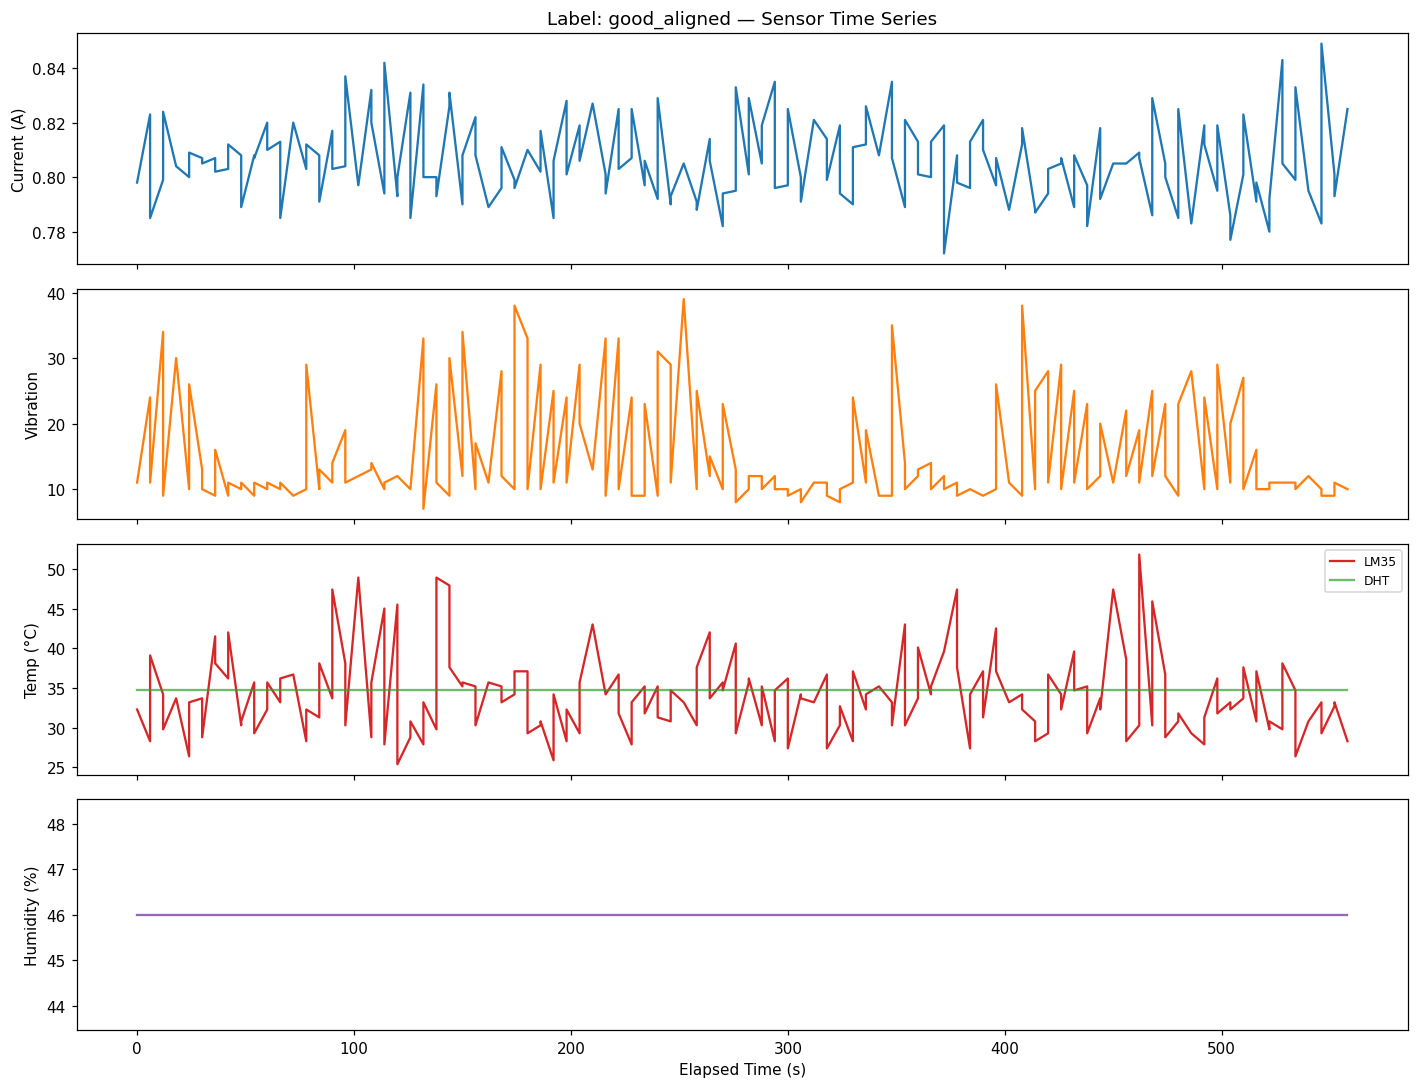

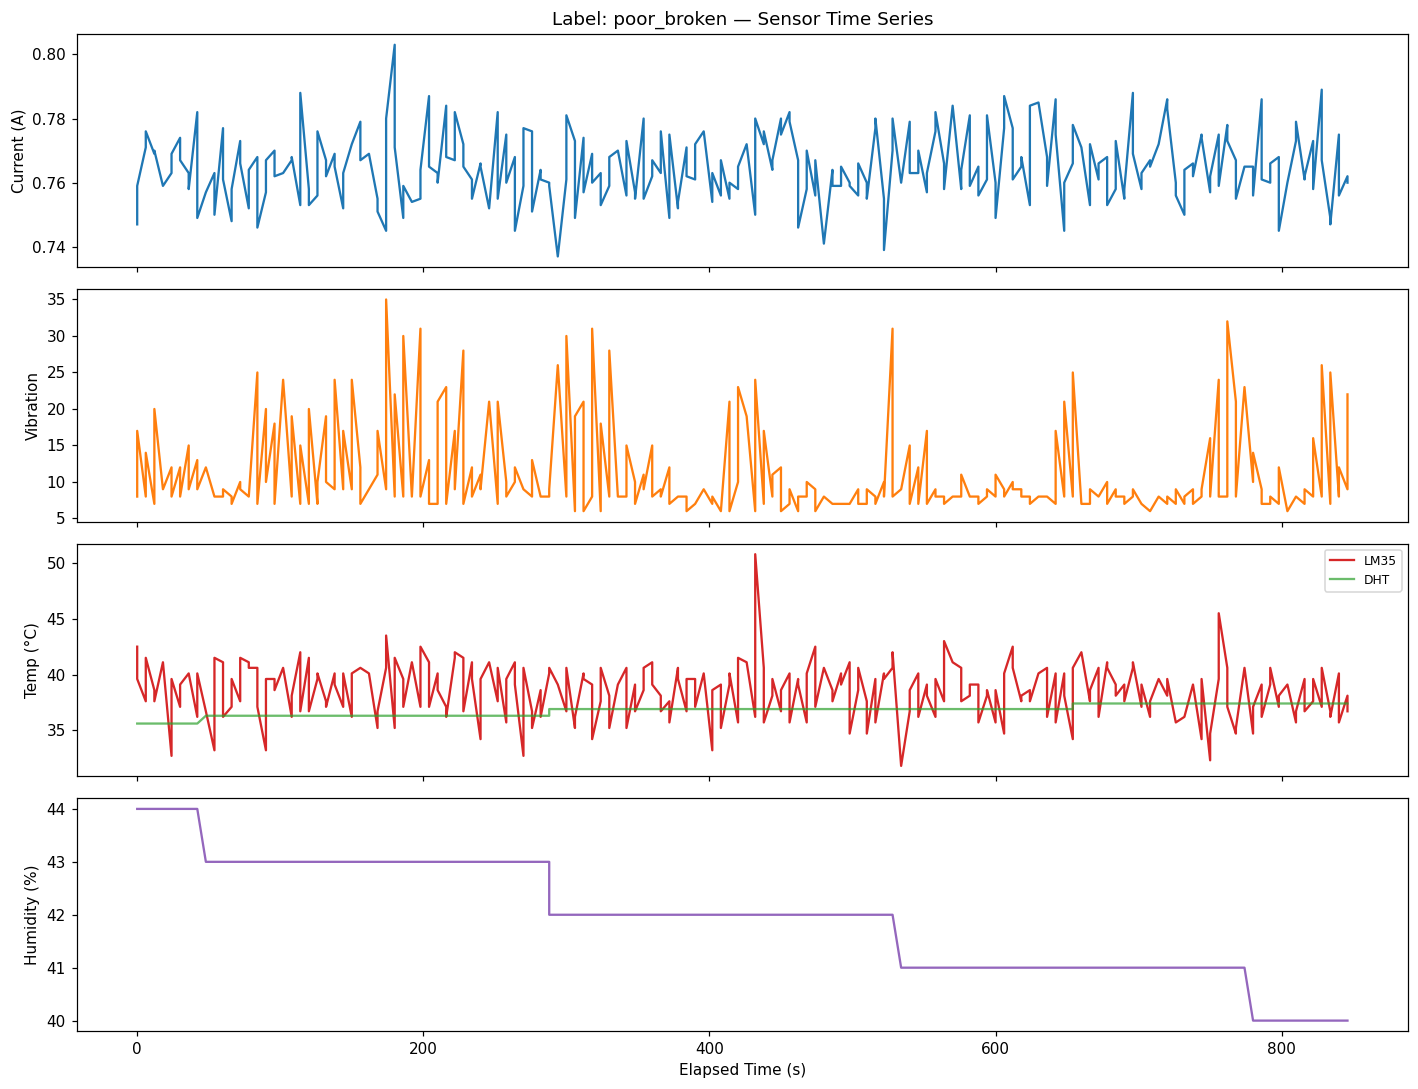

In [ ]:
# ── 8.1 Sensor time-series for one trial of each quality group ───
for label in ['good_aligned', 'poor_broken']:
    tid = processed_df[processed_df['Label'] == label]['Global_Trial'].iloc[0]
    tdf = processed_df[processed_df['Global_Trial'] == tid].reset_index(drop=True)
    plot_sensor_timeseries(tdf, title=f'Label: {label}')

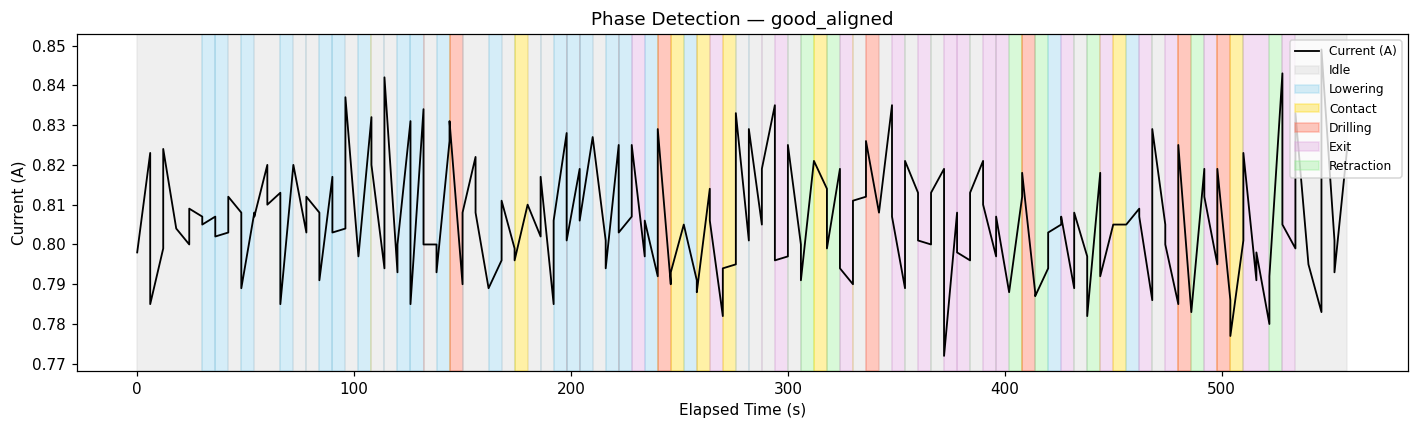

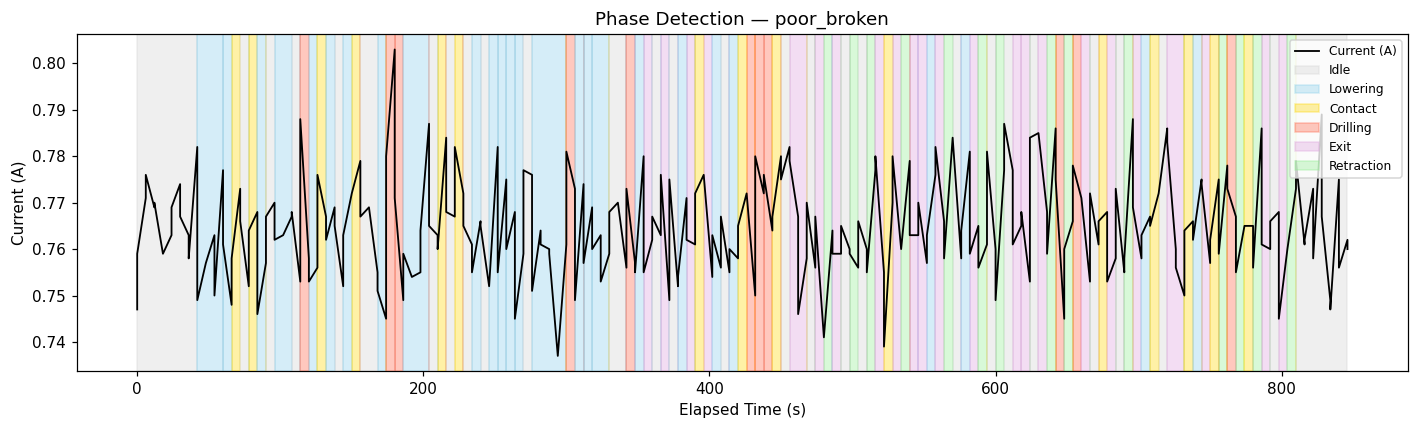

In [ ]:
# ── 8.2 Phase detection overlay ──────────────────────────────────
for label in ['good_aligned', 'poor_broken']:
    tid = processed_df[processed_df['Label'] == label]['Global_Trial'].iloc[0]
    tdf = processed_df[processed_df['Global_Trial'] == tid].reset_index(drop=True)
    plot_phase_detection(tdf, title=f'Phase Detection — {label}')

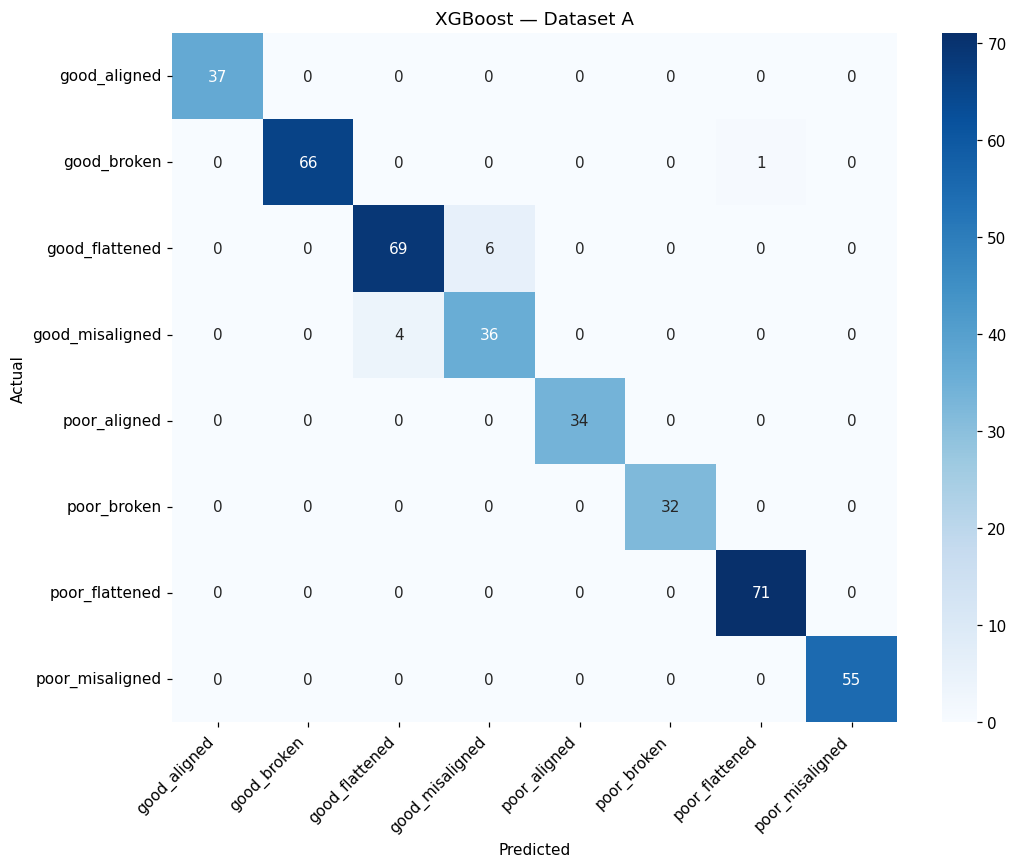

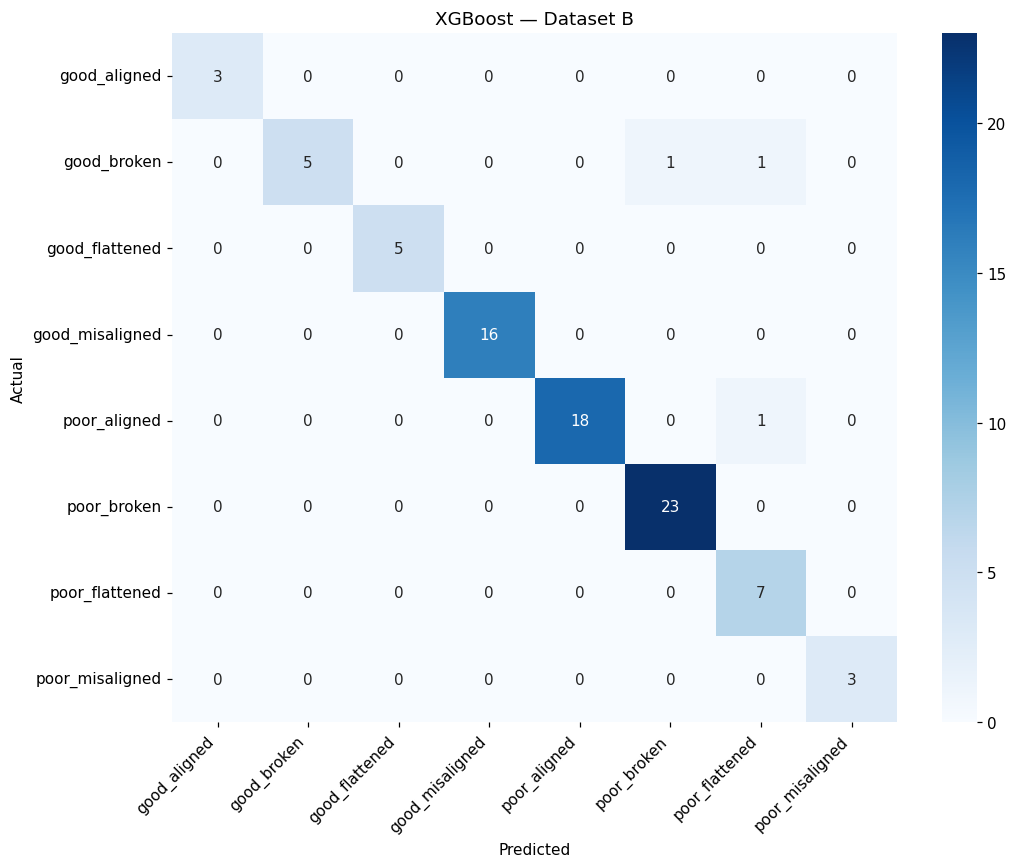

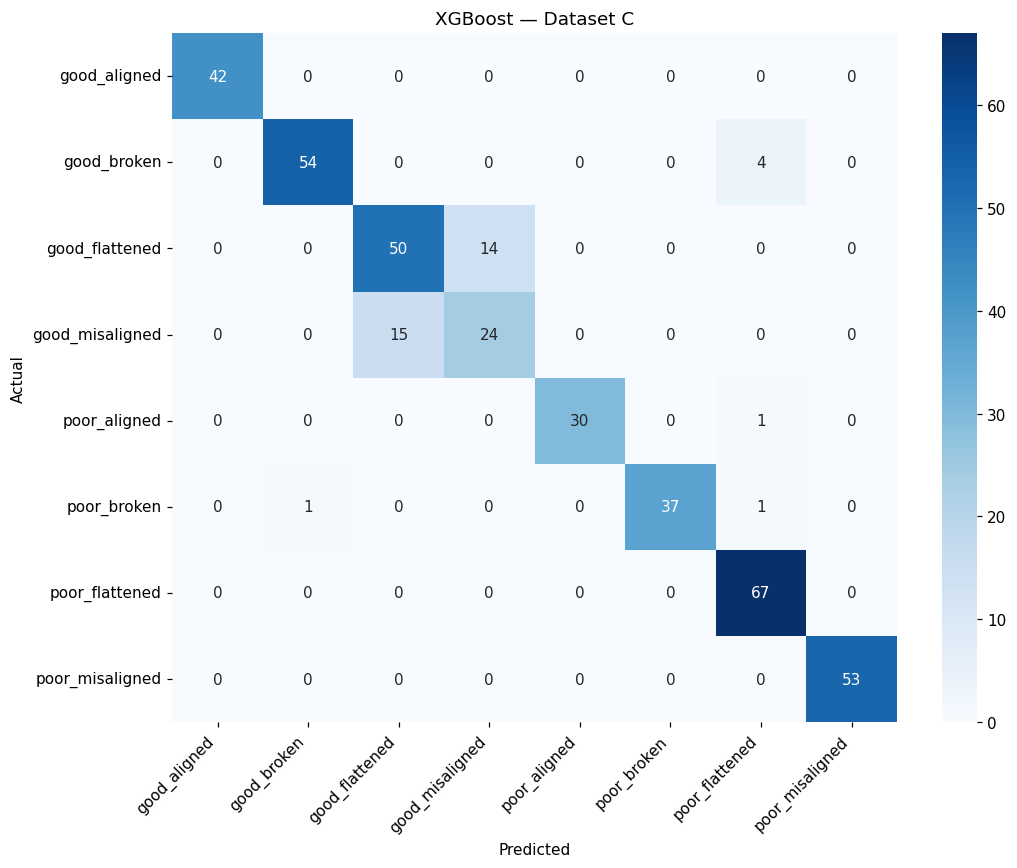

In [ ]:
# ── 8.3 Confusion matrices for best model (XGBoost) ──────────────
for variant, results, le in [('A', results_A, le_A), ('B', results_B, le_B), ('C', results_C, le_C)]:
    r = results['XGBoost']
    plot_confusion_matrix(r['y_test'], r['y_pred'], le.classes_,
                          title=f'XGBoost — Dataset {variant}')

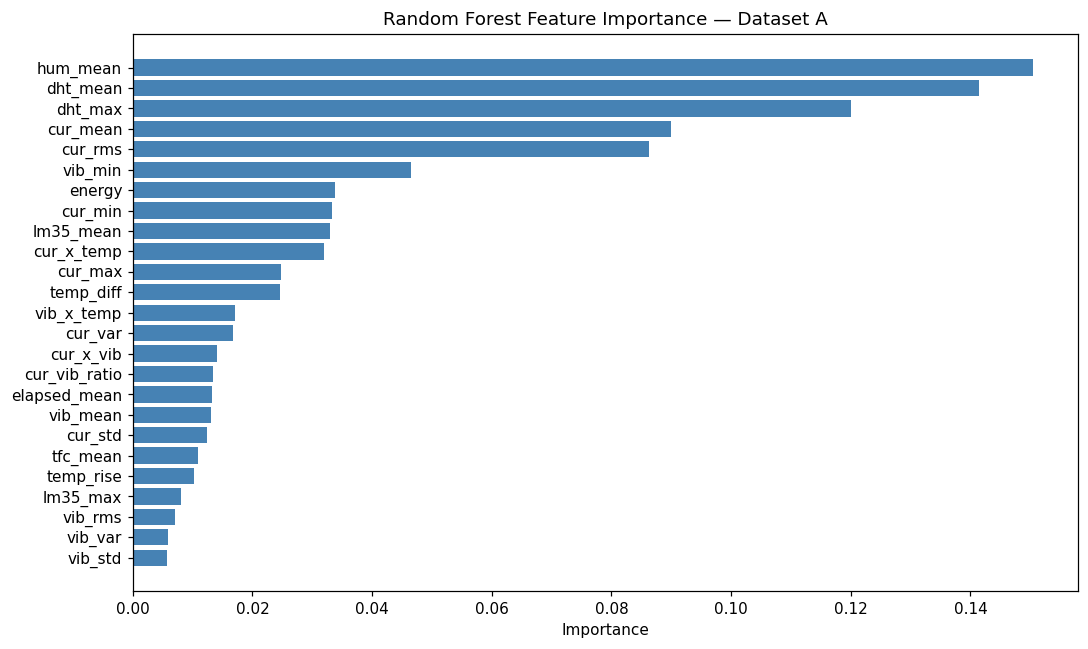

In [ ]:
# ── 8.4 Feature importance (Random Forest on Dataset A) ──────────
rf_model     = results_A['Random Forest']['model']
feature_cols = [c for c in dataset_A.columns if c not in ('Label','Global_Trial')]
plot_feature_importance(rf_model, feature_cols, top_n=25,
                        title='Random Forest Feature Importance — Dataset A')

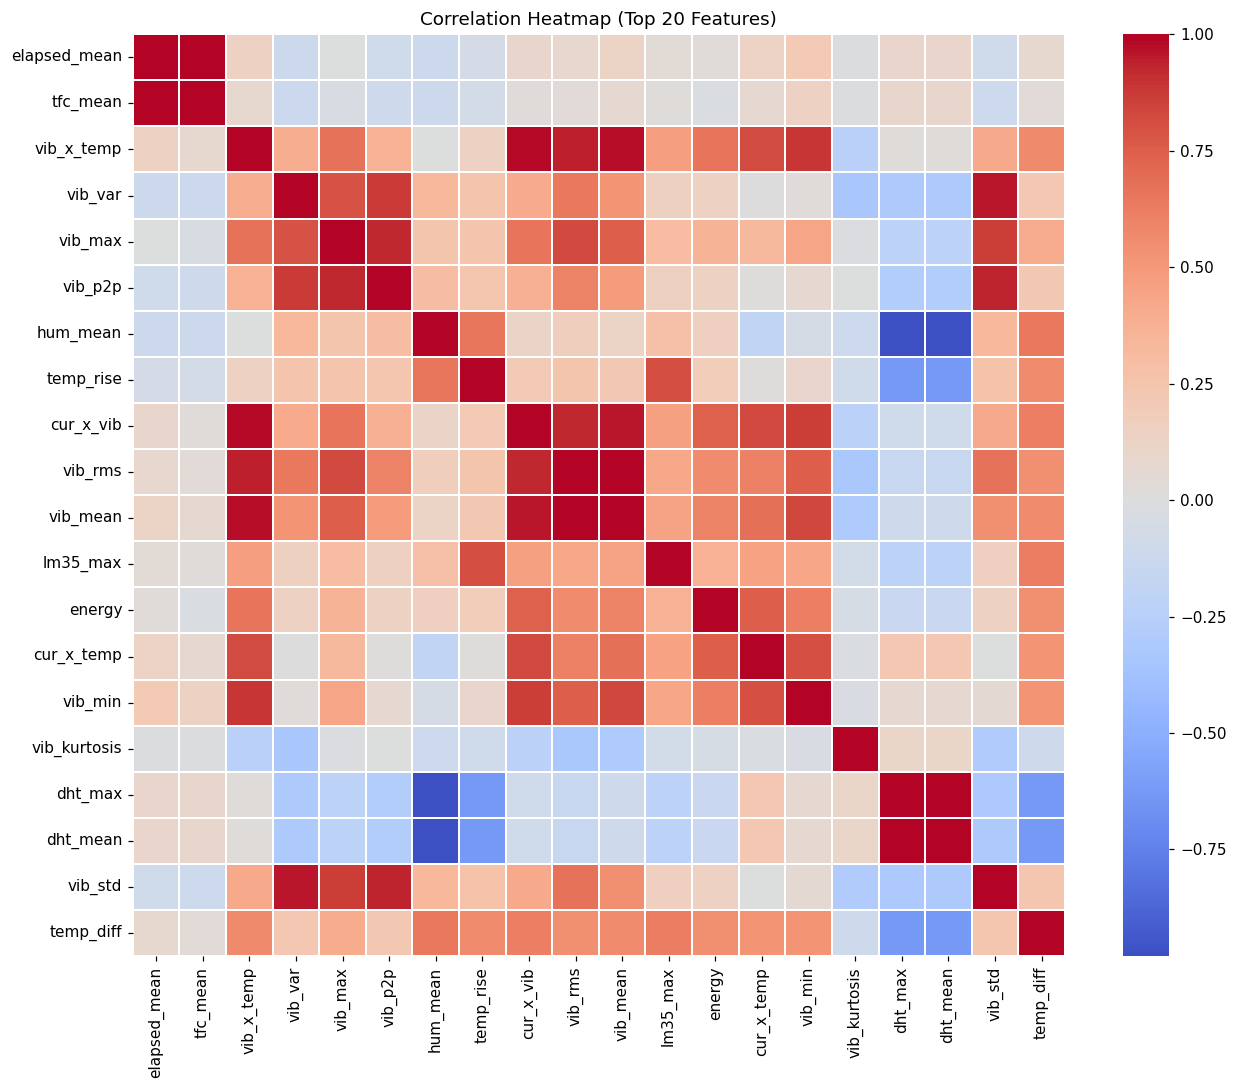

In [ ]:
# ── 8.5 Correlation heatmap ───────────────────────────────────────
plot_correlation_heatmap(dataset_A, top_n=20)

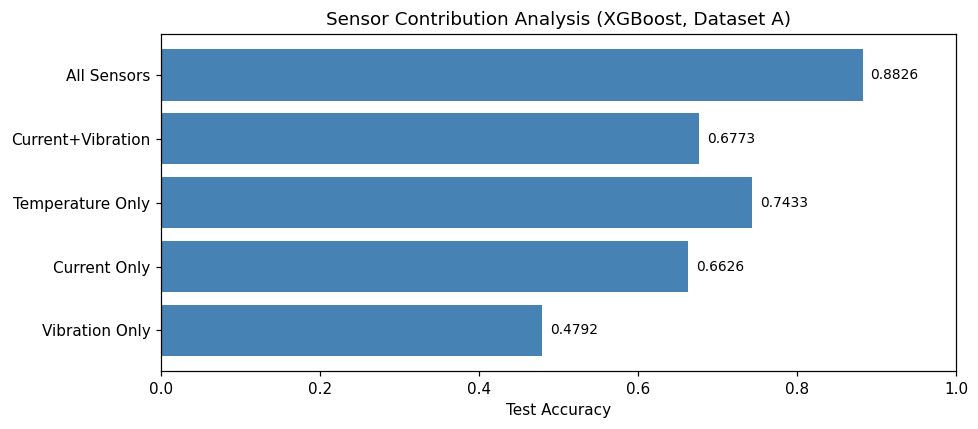

In [ ]:
# ── 8.6 Sensor contribution bar chart ────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(list(sensor_results.keys()), list(sensor_results.values()), color='steelblue')
ax.set_xlabel('Test Accuracy')
ax.set_title('Sensor Contribution Analysis (XGBoost, Dataset A)')
ax.set_xlim(0, 1)
for i, (k, v) in enumerate(sensor_results.items()):
    ax.text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

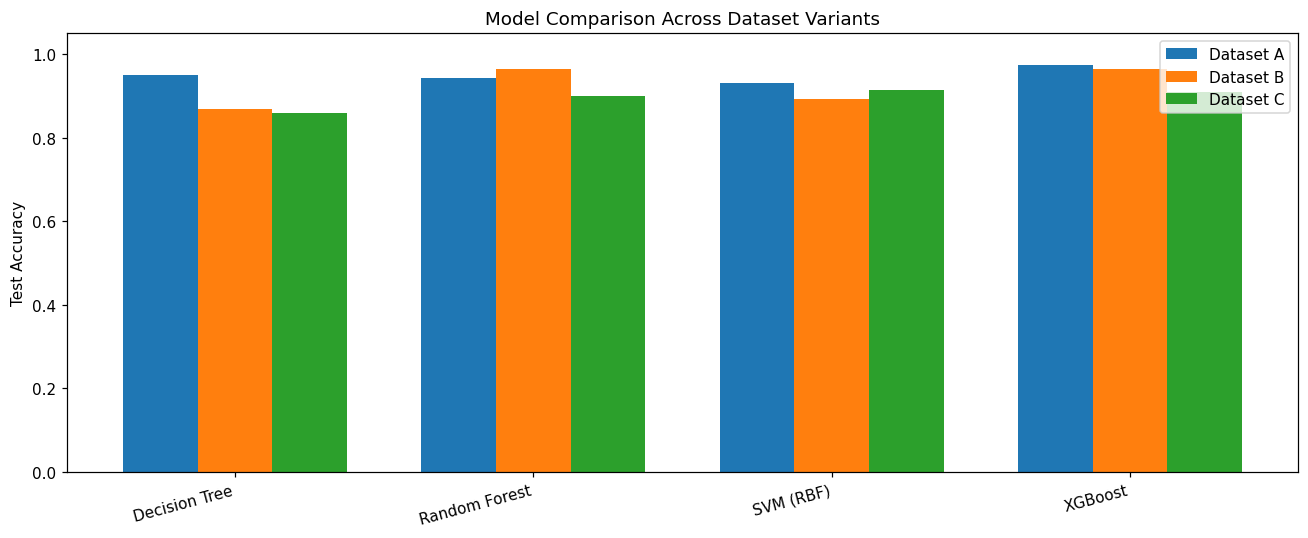

In [ ]:
# ── 8.7 Model comparison across dataset variants ──────────────────
model_names = list(results_A.keys())
variants    = {'A': results_A, 'B': results_B, 'C': results_C}

x  = np.arange(len(model_names))
w  = 0.25
fig, ax = plt.subplots(figsize=(12, 5))
for i, (v, res) in enumerate(variants.items()):
    accs = [res[m]['test_acc'] for m in model_names]
    ax.bar(x + (i - 1) * w, accs, width=w, label=f'Dataset {v}')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.set_ylabel('Test Accuracy')
ax.set_title('Model Comparison Across Dataset Variants')
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

## 9 — Summary Table
Consolidate all results into a readable DataFrame.

In [ ]:
rows = []
for variant, results in [('A', results_A), ('B', results_B), ('C', results_C)]:
    for mname, r in results.items():
        rows.append({
            'Dataset': variant,
            'Model':   mname,
            'CV Mean': round(r['cv_mean'], 4),
            'CV Std':  round(r['cv_std'],  4),
            'Train Acc': round(r['train_acc'], 4),
            'Val Acc':   round(r['val_acc'],   4),
            'Test Acc':  round(r['test_acc'],  4),
            'Test F1':   round(r['test_f1'],   4),
        })

summary_df = pd.DataFrame(rows)
summary_df.sort_values(['Dataset','Test Acc'], ascending=[True, False], inplace=True)
summary_df.reset_index(drop=True, inplace=True)
summary_df

,Dataset,Model,CV Mean,CV Std,Train Acc,Val Acc,Test Acc,Test F1
0,A,XGBoost,0.8892,0.0293,1.0000,0.9289,0.9732,0.9734
1,A,Decision Tree,0.7929,0.1053,1.0000,0.8063,0.9489,0.9497
2,A,Random Forest,0.8717,0.0263,0.9977,0.9051,0.9416,0.9416
3,A,SVM (RBF),0.8680,0.0377,0.9886,0.9012,0.9319,0.9326
4,B,Random Forest,0.8947,0.0761,1.0000,0.9333,0.9639,0.9633
5,B,XGBoost,0.8982,0.0581,1.0000,0.9333,0.9639,0.9633
6,B,SVM (RBF),0.8175,0.0614,0.9930,0.9167,0.8916,0.8757
7,B,Decision Tree,0.7544,0.1126,1.0000,0.9167,0.8675,0.8433
8,C,SVM (RBF),0.8325,0.0256,0.9948,0.9048,0.9135,0.9125
9,C,XGBoost,0.9043,0.0679,1.0000,0.9524,0.9084,0.9083
